# Exploring Support Vector Machines

**NOTE: For this example, we will explore the algorithm, so we'll skip scaling and also skip a train\test split and instead see how the various parameters can change an SVM (easiest to visualize the effects in classification)**

[Link to a great Paper on SVM](http://citeseerx.ist.psu.edu/viewdoc/download;jsessionid=4448154647BC7B10C991CEF2236BBA38?doi=10.1.1.114.4288&rep=rep1&type=pdf)
* A tutorial on support vector regression by ALEX J. SMOLA and BERNHARD SCHOLKOPF

## SVM - Classification

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Data

The data presented here represents a simulated medical study involving mice infected with a virus. These mice were administered different doses of two distinct medicines. Subsequently, they were monitored after a 2-week period to determine if the virus infection persisted. 

The objective with this dataset is to develop a classification model that can predict, based on two dosage measurements, whether the mouse will remain infected with the virus.

It is evident that the groups in the dataset are intentionally made highly separable. This deliberate separation allows us to investigate and analyze the behavior of different parameters in an SVM (Support Vector Machine) model.


In [2]:
df = pd.read_csv(r"C:\Users\fafzali\Downloads\Machine learning\Code\Week#7\mouse_viral_study.csv")

In [3]:
df.head()

,Med_1_mL,Med_2_mL,Virus Present
0,6.508231,8.582531,0
1,4.126116,3.073459,1
2,6.427870,6.369758,0
3,3.672953,4.905215,1
4,1.580321,2.440562,1


In [4]:
df.columns

Index(['Med_1_mL', 'Med_2_mL', 'Virus Present'], dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Med_1_mL       400 non-null    float64
 1   Med_2_mL       400 non-null    float64
 2   Virus Present  400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


## Classes

<Axes: xlabel='Med_1_mL', ylabel='Med_2_mL'>

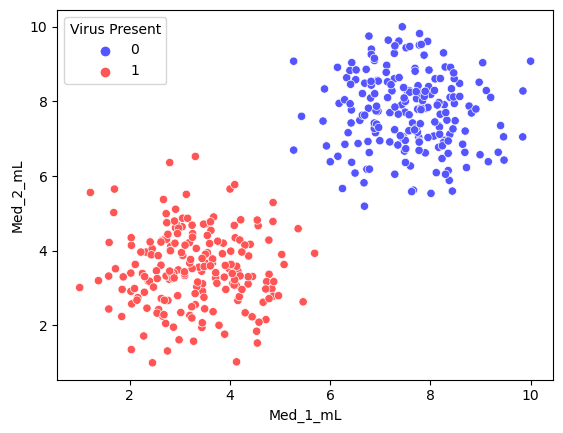

In [6]:
sns.scatterplot(x='Med_1_mL',y='Med_2_mL',hue='Virus Present',
                data=df,palette='seismic')

.
## Separating Hyperplane

Our objective in utilizing Support Vector Machines (SVM) is to construct the optimal separating hyperplane. In a two-dimensional space, this translates to a straightforward line.


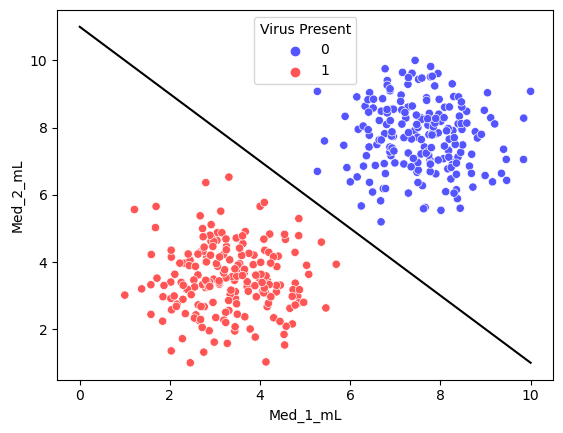

In [7]:
# We begin by creating a scatterplot using Seaborn to visualize data points in a 2D space.
# The 'Med_1_mL' column is plotted on the x-axis, 'Med_2_mL' on the y-axis, and the color of the points is determined by the 'Virus Present' column.
# We use the 'seismic' colormap to color the points, which provides a distinct color mapping for positive and negative values.
sns.scatterplot(x='Med_1_mL', y='Med_2_mL', hue='Virus Present', palette='seismic', data=df)

# Now, we have the objective to automatically create a separating hyperplane in this 2D space.
# The following code manually plots a straight line, which can be considered as a separating hyperplane.
# It's important to note that in practice, we usually use machine learning models to find such separating hyperplanes.
# This manual approach is for illustration purposes.
# We create an array of 100 evenly spaced 'x' values from 0 to 10.
x = np.linspace(0, 10, 100)

# Next, we define the slope 'm' and y-intercept 'b' of the line equation.
# Here, 'm' is set to -1, which represents the slope of the line.
m = -1
# 'b' is set to 11, which represents the y-intercept of the line.
b = 11

# Using the slope-intercept form of a line equation (y = mx + b), we calculate 'y' values for each 'x' in the range.
y = m * x + b

# Finally, we use Matplotlib to plot the line on the same graph.
# The line is drawn in black ('k') color.
plt.plot(x, y, 'k')

# This code visually demonstrates how a manual separating hyperplane (a straight line in 2D) can be created.


## SVM - Support Vector Machine

In [8]:
from sklearn.svm import SVC # Supprt Vector Classifier

In [9]:
help(SVC)

Help on class SVC in module sklearn.svm._classes:

class SVC(sklearn.svm._base.BaseSVC)
 |  SVC(*, C=1.0, kernel='rbf', degree=3, gamma='scale', coef0=0.0, shrinking=True, probability=False, tol=0.001, cache_size=200, class_weight=None, verbose=False, max_iter=-1, decision_function_shape='ovr', break_ties=False, random_state=None)
 |  
 |  C-Support Vector Classification.
 |  
 |  The implementation is based on libsvm. The fit time scales at least
 |  quadratically with the number of samples and may be impractical
 |  beyond tens of thousands of samples. For large datasets
 |  consider using :class:`~sklearn.svm.LinearSVC` or
 |  :class:`~sklearn.linear_model.SGDClassifier` instead, possibly after a
 |  :class:`~sklearn.kernel_approximation.Nystroem` transformer or
 |  other :ref:`kernel_approximation`.
 |  
 |  The multiclass support is handled according to a one-vs-one scheme.
 |  
 |  For details on the precise mathematical formulation of the provided
 |  kernel functions and how `g

**NOTE: For this example, we will explore the algorithm, so we'll skip any scaling or even a train\test split for now**

In [10]:
y = df['Virus Present']
X = df.drop('Virus Present',axis=1) 

In [11]:
y

0      0
1      1
2      0
3      1
4      1
      ..
395    1
396    0
397    0
398    1
399    0
Name: Virus Present, Length: 400, dtype: int64

In [12]:
# We are using the Support Vector Machine (SVM) classifier with a linear kernel to create a separating hyperplane.
# SVM is a powerful machine learning algorithm used for classification tasks, and a linear kernel implies a linear decision boundary.

# First, we create an SVM model with the 'SVC' (Support Vector Classification) class from the scikit-learn library.
# We specify 'kernel='linear'' to use a linear kernel, and 'C=1000' is a regularization parameter.
model = SVC(kernel='linear', C=1000)

# Next, we train the SVM model on the input data (X) and corresponding labels (y).
# The 'fit' method is used to perform the training, where the model learns to find the best separating hyperplane.
model.fit(X, y)

# After training, the 'model' variable contains the trained SVM classifier, which can be used for making predictions on new data.

# SVMs are particularly useful for tasks where we need to find a hyperplane that best separates data points of different classes.
# The 'linear' kernel assumes a linear decision boundary, which is a straight line in 2D space. For higher dimensions, it's a hyperplane.
# The 'C' parameter controls the trade-off between maximizing the margin (the distance between the hyperplane and nearest data points) and minimizing classification errors.
# Higher values of 'C' indicate a smaller margin but fewer misclassifications, while lower values prioritize a larger margin with more misclassifications.

# Overall, this code performs SVM classification with a linear kernel and demonstrates how to train the model using labeled data.


SVC(C=1000, kernel='linear')

In [13]:
# This is imported from the supplemental .py file
# https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane.html
from svm_margin_plot import plot_svm_boundary

# This code is importing a function 'plot_svm_boundary' from an external Python file.
# The purpose of this function is to visualize the separating hyperplane created by a Support Vector Machine (SVM) classifier.

# The 'plot_svm_boundary' function is not provided here, but it is assumed to take certain inputs to generate the visualization.

# To use this function, you typically need to pass the SVM classifier, input data, and labels to it.
# It will then create a scatterplot of the data points, color-coded by class labels.
# Additionally, it will draw the decision boundary (separating hyperplane) created by the SVM model.

# Here's how you might use this function:
# - You would have previously trained an SVM classifier, like the one created using 'model = SVC(kernel='linear', C=1000)' in your previous code.
# - You would have your input data 'X' and corresponding labels 'y'.
# - You pass these variables to 'plot_svm_boundary' to visualize the SVM's decision boundary and how well it separates the data.

# The visualization will help you understand how effective the SVM model is at classifying the data points.

# It's important to note that the specific implementation details of the 'plot_svm_boundary' function are assumed to be in the imported file 'svm_margin_plot.py'.
# You would typically look into that file to understand how the function works and what inputs it expects.


C:\Users\fafzali\AppData\Local\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


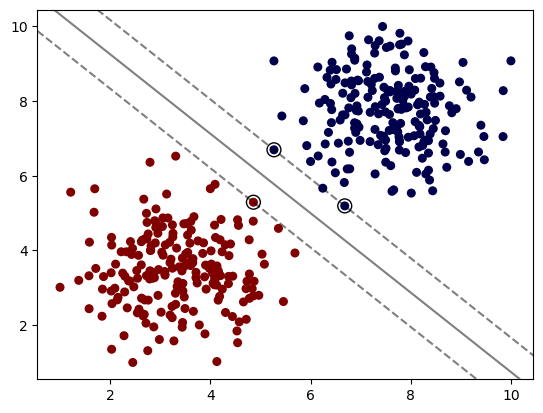

In [14]:
plot_svm_boundary(model,X,y)

## Hyper Parameters

### C

Regularization parameter. The strength of the regularization is **inversely** proportional to C. Must be strictly positive. The penalty is a squared l2 penalty.

*Note: If you are following along with the equations, specifically the value of C as described in ISLR, C in scikit-learn is **inversely** proportional to this value.*

In [30]:
model = SVC(kernel='linear', C=0.01)
model.fit(X, y)

SVC(C=0.01, kernel='linear')

C:\Users\fafzali\AppData\Local\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


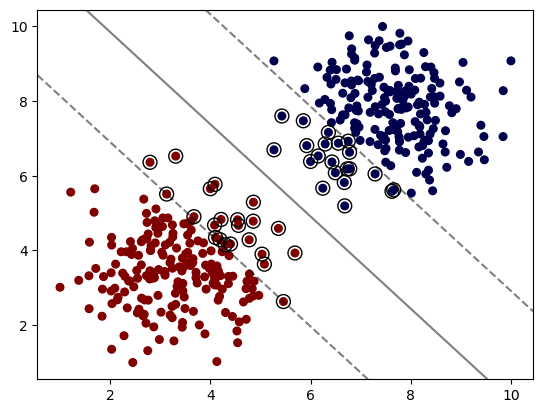

In [31]:
plot_svm_boundary(model,X,y)

### Kernel

[Choosing a Kernel](https://stats.stackexchange.com/questions/18030/how-to-select-kernel-for-svm?rq=1)

#### rbf - [Radial Basis Function](https://en.wikipedia.org/wiki/Radial_basis_function_kernel)

When conducting training for a Support Vector Machine (SVM) employing the Radial Basis Function (RBF) kernel, two crucial parameters demand attention: C and gamma.

The parameter C, which is a universal feature across SVM kernels, balances the trade-off between misclassifying training instances and the simplicity of the decision boundary. Lower values of C yield smoother decision boundaries, while higher values of C prioritize the accurate classification of all training examples.

On the other hand, gamma plays a pivotal role in determining the influence of individual training examples. A higher gamma implies that other examples need to be closer to have an impact on the decision boundary, effectively creating a more localized influence.


C:\Users\fafzali\AppData\Local\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


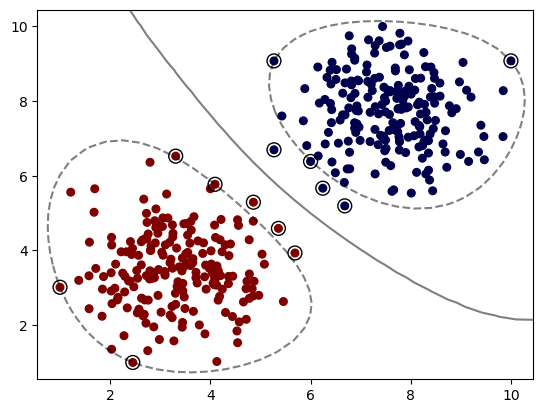

In [17]:
# Import the SVC (Support Vector Machine) classifier from scikit-learn
from sklearn.svm import SVC

# Create an SVM classifier with an RBF (Radial Basis Function) kernel and regularization parameter C=1
# Explanation: We start by importing the SVC (Support Vector Machine) classifier from the scikit-learn library. 
# This classifier is used for performing Support Vector Machine classification tasks.
model = SVC(kernel='rbf', C=1)
# Explanation: Next, we create an instance of the SVC classifier named 'model'. 
# We specify that we want to use an RBF (Radial Basis Function) kernel by setting 'kernel='rbf''. 
# The RBF kernel is effective for capturing non-linear decision boundaries.

# Train the SVM model on the input data 'X' and corresponding labels 'y'
# Explanation: We set the regularization parameter 'C' to 1. This parameter controls the trade-off 
# between maximizing the margin and minimizing classification errors. Smaller 'C' values encourage a wider margin 
# but may tolerate some misclassification, while larger 'C' values prioritize correct classification of training data.
model.fit(X, y)
# Explanation: We proceed to train the SVM model by calling the 'fit' method on the input data 'X' and 
# the corresponding labels 'y'. During training, the SVM algorithm optimizes the decision boundary 
# to effectively separate the data into different classes.

# Visualize the decision boundary using the 'plot_svm_boundary' function
# Explanation: Finally, we use the 'plot_svm_boundary' function to visualize the decision boundary learned 
# by the SVM model. This function takes the trained model, the input data 'X', and the labels 'y' as arguments 
# and generates a graphical representation of how well the SVM separates the data.
plot_svm_boundary(model, X, y)


C:\Users\fafzali\AppData\Local\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


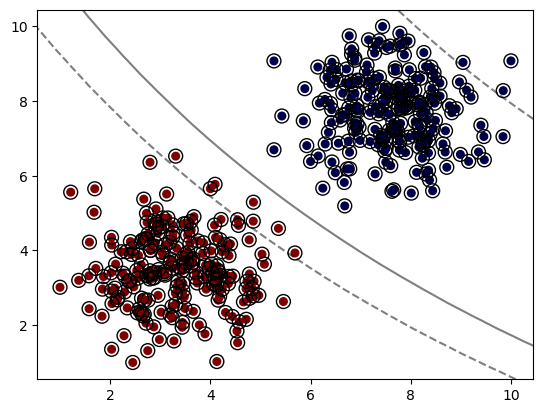

In [18]:
model = SVC(kernel='sigmoid')
model.fit(X, y)
plot_svm_boundary(model,X,y)

#### Degree (poly kernels only)

Degree of the polynomial kernel function ('poly').
Ignored by all other kernels.

C:\Users\fafzali\AppData\Local\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


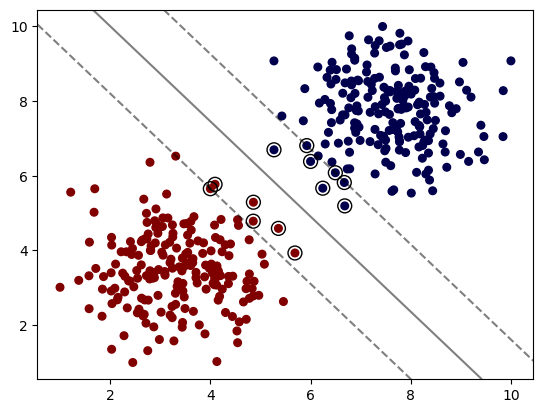

In [19]:
# Import the SVC (Support Vector Machine) classifier from scikit-learn
from sklearn.svm import SVC

# Create an SVM classifier with a polynomial kernel (degree=1) and regularization parameter C=1
# Explanation: We start by importing the SVC (Support Vector Machine) classifier from the scikit-learn library. 
# This classifier is used for performing Support Vector Machine classification tasks.
model = SVC(kernel='poly', C=1, degree=1)
# Explanation: Next, we create an instance of the SVC classifier named 'model'. 
# We specify that we want to use a polynomial kernel with degree 1 by setting 'kernel='poly'' and 'degree=1'. 
# The polynomial kernel can capture certain types of non-linear decision boundaries.

# Train the SVM model on the input data 'X' and corresponding labels 'y'
# Explanation: We set the regularization parameter 'C' to 1. This parameter controls the trade-off 
# between maximizing the margin and minimizing classification errors. Smaller 'C' values encourage a wider margin 
# but may tolerate some misclassification, while larger 'C' values prioritize correct classification of training data.
model.fit(X, y)
# Explanation: We proceed to train the SVM model by calling the 'fit' method on the input data 'X' and 
# the corresponding labels 'y'. During training, the SVM algorithm optimizes the decision boundary 
# to effectively separate the data into different classes.

# Visualize the decision boundary using the 'plot_svm_boundary' function
# Explanation: Finally, we use the 'plot_svm_boundary' function to visualize the decision boundary learned 
# by the SVM model. This function takes the trained model, the input data 'X', and the labels 'y' as arguments 
# and generates a graphical representation of how well the SVM separates the data.
plot_svm_boundary(model, X, y)


C:\Users\fafzali\AppData\Local\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


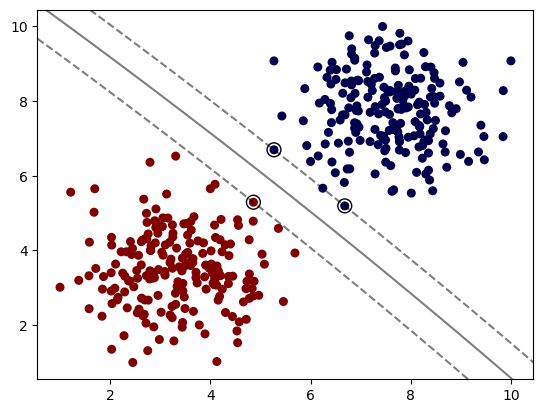

In [20]:
model = SVC(kernel='poly', C=1,degree=2)
model.fit(X, y)
plot_svm_boundary(model,X,y)

### Gamma Parameter Explanation

The gamma parameter in Support Vector Machines (SVM) serves as a crucial factor in various kernel functions, including 'rbf', 'poly', and 'sigmoid'. Its value greatly influences the shape and flexibility of the decision boundary.

Gamma can be computed as follows:

- When `gamma='scale'` (the default option):



gamma = 1 / (n_features * X.var())



- Alternatively, when `gamma='auto'`:



gamma = 1 / n_features


The choice between 'scale' and 'auto' can have a substantial impact on the SVM model's performance and the shape of the decision boundary. Adjusting gamma allows you to control the level of influence each training example has on the decision boundary. A smaller gamma results in a more widespread influence, while a larger gamma makes the influence more localized.


C:\Users\fafzali\AppData\Local\anaconda3\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


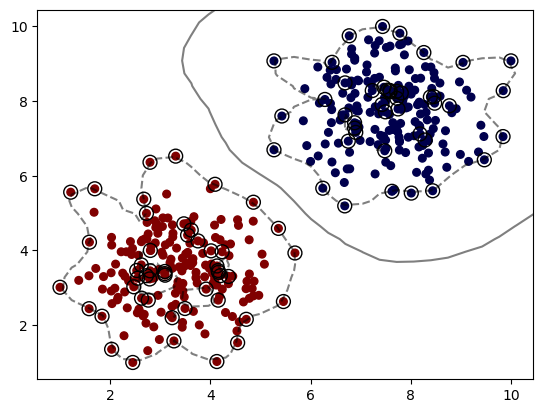

In [24]:
model = SVC(kernel='rbf', C=1,gamma=1)
model.fit(X, y)
plot_svm_boundary(model,X,y)

## Grid Search

Keep in mind, for this simple example, we saw the classes were easily separated, which means each variation of model could easily get 100% accuracy, meaning a grid search is "useless".

In [25]:
from sklearn.model_selection import GridSearchCV

In [26]:
# Import the SVC (Support Vector Machine) classifier and GridSearchCV from scikit-learn
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Create an instance of the SVM classifier
# Explanation: We create an instance of the SVC (Support Vector Machine) classifier named 'svm'.
svm = SVC()

# Define a parameter grid for hyperparameter tuning
# Explanation: We define a parameter grid 'param_grid' that specifies a range of hyperparameter values 
# we want to search over during grid search.
param_grid = {'C': [0.01, 0.1, 1], 'kernel': ['linear', 'rbf']}
# Explanation: In this case, we specify values for the regularization parameter 'C' and the kernel type. 
# We want to search for the best combination of 'C' values (0.01, 0.1, 1) and kernel types ('linear' and 'rbf').

# Create an instance of GridSearchCV for hyperparameter tuning
# Explanation: We create an instance of GridSearchCV named 'grid'. GridSearchCV is a method for systematically 
# searching for the best hyperparameters for a machine learning model.
grid = GridSearchCV(svm, param_grid)
# Explanation: We pass our SVM classifier 'svm' and the parameter grid 'param_grid' to GridSearchCV. 
# GridSearchCV will perform a search over the specified hyperparameter values and combinations to find 
# the best-performing model.


In [27]:
# Note again we didn't split Train|Test
grid.fit(X,y)

GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.01, 0.1, 1], 'kernel': ['linear', 'rbf']})

In [28]:
# 100% accuracy (as expected)
grid.best_score_

1.0

In [29]:
grid.best_params_

{'C': 0.01, 'kernel': 'linear'}

This is more to review the grid search process, recall in a real situation such as your exercise, you will perform a train|test split and get final evaluation metrics.